In [1]:
import sys; sys.path.append("..")
import time
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, matthews_corrcoef
from src.data import load_data
from src.config import TEST_DIR
from src.pipelines import get_finalists
from src.bootstrap import ci_report, paired_bootstrap_diff, mcnemar_exact

X_train, X_test, y_train, y_test, labels = load_data()
y_true = y_test.to_numpy()

da_khoa = pd.read_csv(TEST_DIR / "final_predictions.csv")
assert (da_khoa["y_true"].to_numpy() == y_true).all()
du_doan = {"hgb_N1_balanced_da_khoa": da_khoa["y_pred"].to_numpy()}

for ten, model in get_finalists().items():
    t0 = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    du_doan[ten] = pred
    pd.DataFrame({"y_true": y_true, "y_pred": pred}).to_csv(
        TEST_DIR / f"supp_{ten}_predictions.csv", index=False)
    print(ten, "xong sau", round(time.time() - t0, 1), "giay")

hgbT_N2_under xong sau 7.7 giay
random_forest_tuned xong sau 1.3 giay
xgb_default xong sau 14.0 giay


In [2]:
rows = []
for ten, pred in du_doan.items():
    macro, bang = ci_report(y_true, pred, labels, n_boot=1000)
    rows.append({
        "mo_hinh": ten,
        "macro_f1": round(macro["macro_f1"], 4),
        "ci_thap": round(macro["ci_thap"], 4),
        "ci_cao": round(macro["ci_cao"], 4),
        "balanced_acc": round(balanced_accuracy_score(y_true, pred), 4),
        "mcc": round(matthews_corrcoef(y_true, pred), 4),
        "accuracy": round(accuracy_score(y_true, pred), 4),
        "so_loi": int((pred != y_true).sum()),
        "loi_metasploit": int(((y_true == 4) & (pred != 4)).sum()),
        "loi_fin": int(((y_true == 5) & (pred != 5)).sum()),
    })
tong = pd.DataFrame(rows)
tong.to_csv(TEST_DIR / "supp_test_comparison.csv", index=False)
tong

,mo_hinh,macro_f1,ci_thap,ci_cao,balanced_acc,mcc,accuracy,so_loi,loi_metasploit,loi_fin
0,hgb_N1_balanced_da_khoa,0.9951,0.9918,0.9975,0.9957,0.9967,0.9986,32,0,0
1,hgbT_N2_under,0.9943,0.9904,0.9969,0.9930,0.9952,0.9980,46,0,0
2,random_forest_tuned,0.9886,0.9713,0.9964,0.9917,0.9953,0.9981,45,0,0
3,xgb_default,0.9938,0.9903,0.9965,0.9926,0.9952,0.9980,46,0,0


In [3]:
goc = "hgb_N1_balanced_da_khoa"
rows = []
for ten, pred in du_doan.items():
    if ten == goc:
        continue
    d = paired_bootstrap_diff(y_true, du_doan[goc], pred)
    m = mcnemar_exact(y_true, du_doan[goc], pred)
    rows.append({
        "mo_hinh": ten,
        "hieu_macro_f1_so_voi_da_khoa": round(d["hieu_macro_f1"], 4),
        "ci_thap": round(d["ci_thap"], 4),
        "ci_cao": round(d["ci_cao"], 4),
        "da_khoa_dung_kia_sai": m["a_dung_b_sai"],
        "da_khoa_sai_kia_dung": m["a_sai_b_dung"],
        "p_mcnemar": round(m["p"], 3),
    })
so_sanh = pd.DataFrame(rows)
so_sanh.to_csv(TEST_DIR / "supp_paired_vs_locked.csv", index=False)
so_sanh

,mo_hinh,hieu_macro_f1_so_voi_da_khoa,ci_thap,ci_cao,da_khoa_dung_kia_sai,da_khoa_sai_kia_dung,p_mcnemar
0,hgbT_N2_under,-0.0009,-0.0040,0.0014,21,7,0.013
1,random_forest_tuned,-0.0066,-0.0239,0.0010,21,8,0.024
2,xgb_default,-0.0013,-0.0039,0.0011,18,4,0.004


In [4]:
cap_loi = []
for ten, pred in du_doan.items():
    ts_arp = int(((y_true == 10) & (pred == 0)).sum())
    arp_ts = int(((y_true == 0) & (pred == 10)).sum())
    cap_loi.append({
        "mo_hinh": ten,
        "thingspeak_thanh_arp": ts_arp,
        "arp_thanh_thingspeak": arp_ts,
        "tong_hai_chieu": ts_arp + arp_ts,
        "tong_loi": int((pred != y_true).sum()),
    })
cap = pd.DataFrame(cap_loi)
cap.to_csv(TEST_DIR / "supp_arp_thingspeak_confusion.csv", index=False)
cap

,mo_hinh,thingspeak_thanh_arp,arp_thanh_thingspeak,tong_hai_chieu,tong_loi
0,hgb_N1_balanced_da_khoa,8,11,19,32
1,hgbT_N2_under,20,15,35,46
2,random_forest_tuned,17,16,33,45
3,xgb_default,19,13,32,46


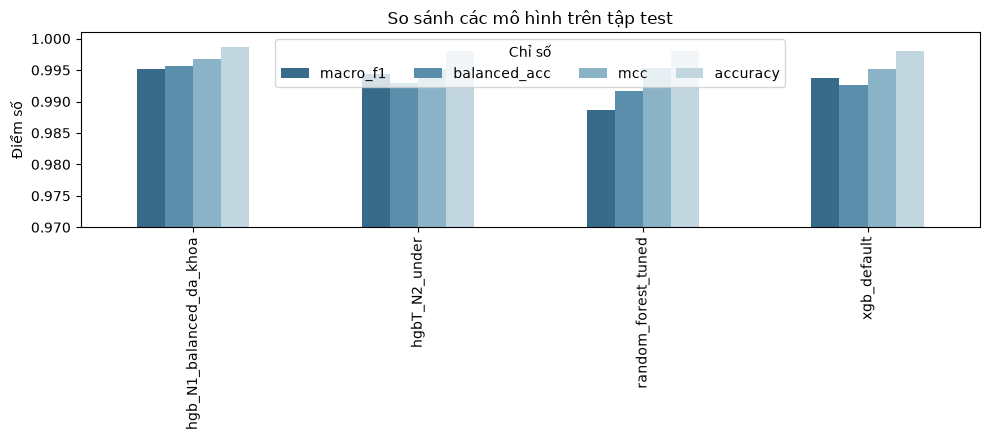

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt

results = (Path('..') if Path.cwd().name == 'experiments' else Path('.')) / 'results'
metrics = tong.set_index('mo_hinh')[['macro_f1', 'balanced_acc', 'mcc', 'accuracy']]
fig, ax = plt.subplots(figsize=(10, 4.5))
metrics.plot.bar(ax=ax, color=['#386A89', '#5B8EAA', '#8BB3C7', '#C2D6E0'])
ax.set(title='So sánh các mô hình trên tập test', ylabel='Điểm số', xlabel='')
ax.set_ylim(0.97, 1.001)
ax.legend(title='Chỉ số', ncol=4)
fig.tight_layout()
(results / 'figures').mkdir(exist_ok=True)
fig.savefig(results / 'figures/supp_test_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

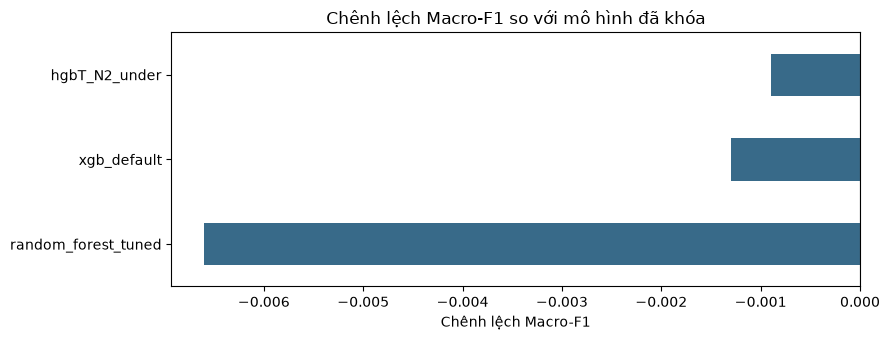

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

results = (Path('..') if Path.cwd().name == 'experiments' else Path('.')) / 'results'
values = so_sanh.set_index('mo_hinh')['hieu_macro_f1_so_voi_da_khoa']
fig, ax = plt.subplots(figsize=(9, 3.5))
values.sort_values().plot.barh(ax=ax, color='#386A89')
ax.axvline(0, color='0.4', linewidth=0.8)
ax.set(title='Chênh lệch Macro-F1 so với mô hình đã khóa', xlabel='Chênh lệch Macro-F1', ylabel='')
fig.tight_layout()
(results / 'figures').mkdir(exist_ok=True)
fig.savefig(results / 'figures/supp_paired_macro_f1_diff.png', dpi=300, bbox_inches='tight')
plt.show()